# Notebook 4 de 4: comparación, interpretación y evaluación final

Este notebook continúa la sesión del notebook 3. Se comparan los algoritmos con el basal en validación cruzada
(M7), se analiza qué variables usan y dónde se equivocan (M8), se abre el test por única vez (M9) y se cierra
con las limitaciones del trabajo (M10).

In [1]:
# Continúa la sesión del notebook 03_Modelos_y_ajuste (correrlo antes si el archivo no existe)
import joblib                 # se importa antes que dill para que joblib guarde los modelos con el pickle estándar
import dill
dill.load_session("artefactos_ml/estado_03.pkl")
dill.extend(False)            # deja el pickle estándar como estaba (lo usan joblib y pandas)
%matplotlib inline
print("Estado cargado desde artefactos_ml/estado_03.pkl")

Estado cargado desde artefactos_ml/estado_03.pkl


## 8.7 M7: Comparación de modelos

Los cuatro algoritmos, con los hiperparámetros ganadores de M5, y el basal se evalúan en **20 folds**: las cuatro
repeticiones de 5 folds (semillas 42 a 45), todas sobre el train. Para cada algoritmo se informa la media y el
desvío de cada métrica, y se comparan de a pares con una **prueba t pareada corregida** para validación
cruzada repetida (Nadeau y Bengio, 2003). La corrección es necesaria porque los folds comparten datos de
entrenamiento y no son independientes; una prueba t común sería demasiado optimista.

**Regla de elección, declarada antes de ver los resultados.** Entre los modelos cuya mejora sobre el basal es
significativa, se elige el más simple que quede dentro de un error estándar del mejor, ordenando la
simplicidad de menor a mayor: regresión logística, Random Forest, XGBoost, CatBoost. Es la regla de un error estándar (Hastie, Tibshirani y
Friedman, *The Elements of Statistical Learning*): no tiene sentido declarar un ganador por diferencias en la
tercera cifra decimal, que quedan dentro del ruido entre folds.
Es la misma advertencia de la notebook *1 - Modelos que votan* de la clase 5.

In [2]:
from scipy import stats as sps


def metricas_folds(nombre, p, semilla_cv):
    # ROC-AUC y AUC-PR de validación en los 5 folds de una repetición, con la configuración ganadora.
    res = []
    for k in range(N_FOLDS):
        Ztr, Zva, ytr, yva = matrices(semilla_cv, k)
        m = construir(nombre, p, SEMILLA)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            if nombre == "XGBoost":
                a, b = interno(semilla_cv, k)
                m.fit(Ztr[a], ytr[a], eval_set=[(Ztr[b], ytr[b])], verbose=False)
                pv = m.predict_proba(Zva, iteration_range=(0, m.best_iteration + 1))[:, 1]
            elif nombre == "CatBoost":
                a, b = interno(semilla_cv, k)
                m.fit(Ztr[a], ytr[a], eval_set=(Ztr[b], ytr[b]), use_best_model=True)
                pv = m.predict_proba(Zva)[:, 1]
            else:
                m.fit(Ztr, ytr)
                pv = m.predict_proba(Zva)[:, 1]
        res.append({"ROC-AUC": roc_auc_score(yva, pv), "AUC-PR": average_precision_score(yva, pv)})
    return res


filas = []
for semilla in SEMILLAS_CV:
    for nombre in ALGORITMOS:
        for k, r in enumerate(metricas_folds(nombre, CONFIG_GANADORA[nombre], semilla)):
            filas.append({"modelo": nombre, "semilla": semilla, "fold": k + 1, **r})
    for k, (tr, va) in enumerate(pares(semilla)):                 # basal en los mismos folds
        k_fold, _, _ = ajustar_regla(tr)                              # regla de M1: puntaje = nivel
        s_va, _ = aplicar_regla(Xm_train[VAR_BASAL].iloc[va], k_fold)
        filas.append({"modelo": "Basal", "semilla": semilla, "fold": k + 1,
                      "ROC-AUC": roc_auc_score(y_ent.iloc[va], s_va),
                      "AUC-PR": average_precision_score(y_ent.iloc[va], s_va)})
folds20 = pd.DataFrame(filas)
for _, r in folds20.iterrows():
    registrar(fase="M7", algoritmo=r["modelo"], semilla=r["semilla"], fold=r["fold"],
              **{"ROC-AUC": r["ROC-AUC"], "AUC-PR": r["AUC-PR"]})
guardar_registro()
folds20.to_csv(ARTEFACTOS / "m7_folds.csv", index=False)

MODELOS = ["Basal"] + ALGORITMOS
roc = folds20.pivot_table(index=["semilla", "fold"], columns="modelo", values="ROC-AUC")[MODELOS]
apr = folds20.pivot_table(index=["semilla", "fold"], columns="modelo", values="AUC-PR")[MODELOS]
N = len(roc)                                                      # 20 folds (4 repeticiones x 5)
FACTOR = 1.0 / N + 1.0 / (N_FOLDS - 1)                            # corrección de Nadeau y Bengio: 1/n + n_test/n_train


def t_corregida(d):
    t = d.mean() / np.sqrt(FACTOR * d.var(ddof=1))
    return t, 2 * sps.t.sf(abs(t), df=N - 1)


tabla_m7 = pd.DataFrame({
    "ROC-AUC (media ± desvío, 20 folds)": [f"{roc[m].mean():.4f} ± {roc[m].std():.4f}" for m in MODELOS],
    "AUC-PR (media ± desvío)": [f"{apr[m].mean():.4f} ± {apr[m].std():.4f}" for m in MODELOS],
    "mejora de ROC-AUC sobre el basal": [np.nan] + [(roc[m] - roc["Basal"]).mean() for m in ALGORITMOS],
    "p (t pareada corregida) vs. basal": [""] + [f"{t_corregida(roc[m] - roc['Basal'])[1]:.1e}" for m in ALGORITMOS],
}, index=MODELOS)
tabla_m7["mejora de ROC-AUC sobre el basal"] = tabla_m7["mejora de ROC-AUC sobre el basal"].round(4)
tabla_m7

,"ROC-AUC (media ± desvío, 20 folds)",AUC-PR (media ± desvío),mejora de ROC-AUC sobre el basal,p (t pareada corregida) vs. basal
Basal,0.6061 ± 0.0057,0.1609 ± 0.0034,NaN,
Regresión logística,0.6705 ± 0.0063,0.2046 ± 0.0050,0.0644,9.2e-15
Random Forest,0.6811 ± 0.0063,0.2212 ± 0.0073,0.0750,4.3e-16
XGBoost,0.6811 ± 0.0063,0.2218 ± 0.0071,0.0751,1.2e-15
CatBoost,0.6828 ± 0.0062,0.2235 ± 0.0066,0.0768,2.1e-16


**Lectura de la tabla.** Los cuatro algoritmos superan al basal por entre 0,064 y 0,077 de ROC-AUC, con
diferencias significativas en todos los casos (p corregido menor que 1e-8). Los tres ensambles quedan juntos
(0,6811 para Random Forest y XGBoost, 0,6828 para CatBoost) y la regresión logística unos 0,011 a 0,012 por
debajo (0,6705). El AUC-PR sigue el mismo orden (0,205, 0,221, 0,222 y 0,224).

Diferencia media de ROC-AUC (fila menos columna):


,Regresión logística,Random Forest,XGBoost,CatBoost
Regresión logística,NaN,-0.0106,-0.0106,-0.0123
Random Forest,0.0106,NaN,-0.0000,-0.0017
XGBoost,0.0106,0.0000,NaN,-0.0017
CatBoost,0.0123,0.0017,0.0017,NaN


p de la prueba t pareada corregida:


,Regresión logística,Random Forest,XGBoost,CatBoost
Regresión logística,,2.03e-07,2.26e-05,5.56e-08
Random Forest,2.03e-07,,0.988,0.0919
XGBoost,2.26e-05,0.988,,0.0993
CatBoost,5.56e-08,0.0919,0.0993,


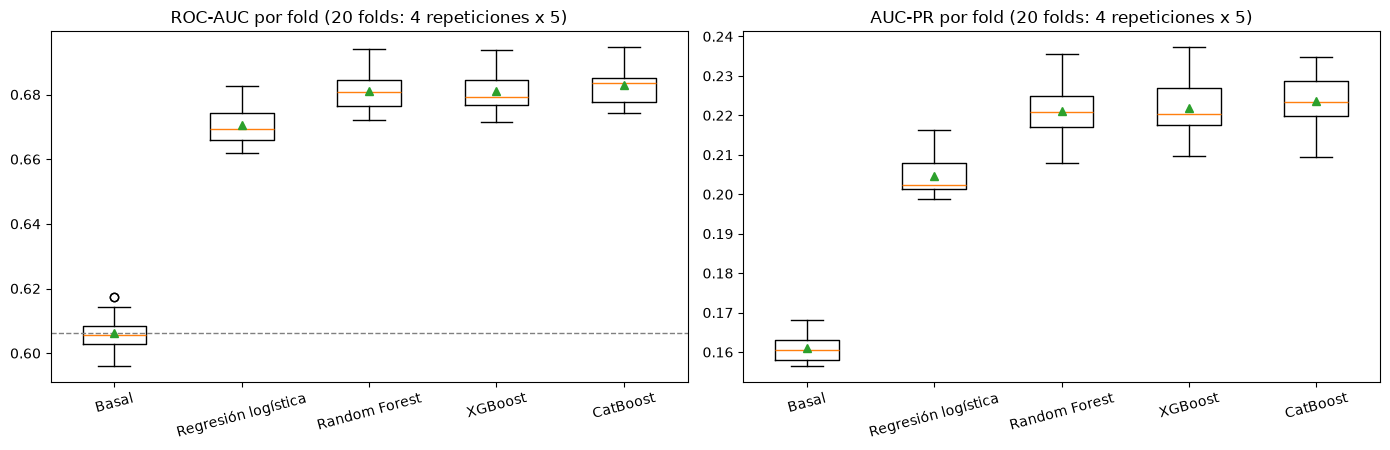

In [3]:
# Comparaciones de a pares entre algoritmos (ROC-AUC): diferencia media (fila menos columna) y p corregido
dif_media = pd.DataFrame(index=ALGORITMOS, columns=ALGORITMOS, dtype=float)
p_val = pd.DataFrame(index=ALGORITMOS, columns=ALGORITMOS, dtype=float)
for a in ALGORITMOS:
    for b in ALGORITMOS:
        if a != b:
            d = roc[a] - roc[b]
            dif_media.loc[a, b], p_val.loc[a, b] = d.mean(), t_corregida(d)[1]
print("Diferencia media de ROC-AUC (fila menos columna):")
display(dif_media.round(4))
print("p de la prueba t pareada corregida:")
display(p_val.map(lambda x: "" if pd.isna(x) else f"{x:.3g}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, tabla, titulo in zip(axes, [roc, apr], ["ROC-AUC", "AUC-PR"]):
    ax.boxplot([tabla[m] for m in MODELOS], tick_labels=MODELOS, showmeans=True)
    ax.set_title(f"{titulo} por fold (20 folds: 4 repeticiones x 5)")
    ax.tick_params(axis="x", rotation=15)
axes[0].axhline(roc["Basal"].mean(), color="gray", ls="--", lw=1)
plt.tight_layout()
plt.show()

**Lectura de las comparaciones.** La regresión logística es peor que los tres ensambles, con una diferencia
de 0,011 a 0,012 que es significativa (p < 0,001 en las tres comparaciones). Entre los ensambles no hay
diferencias significativas: Random Forest y XGBoost son prácticamente idénticos (diferencia de 0,0000, p = 0,99) y
CatBoost se adelanta por 0,0017 (p = 0,09 frente a Random Forest y 0,10 frente a XGBoost), por encima del
umbral convencional de 0,05. En los boxplots, las cajas de los tres ensambles se superponen casi por completo,
están claramente por encima de la regresión logística, y ninguna toca al basal. La dispersión entre folds
(unos 0,006) es mayor que la distancia entre ensambles (0,002 como máximo).

In [4]:
# Regla de elección: entre los modelos que superan significativamente al basal, el más simple dentro de
# un error estándar del mejor (error estándar de la media de 20 folds, con la corrección de Nadeau y Bengio).
orden_simplicidad = ["Regresión logística", "Random Forest", "XGBoost", "CatBoost"]
medias = roc[ALGORITMOS].mean()
mejor = medias.idxmax()
ee_mejor = float(np.sqrt(FACTOR * roc[mejor].var(ddof=1)))
dentro = [m for m in orden_simplicidad if medias[mejor] - medias[m] <= ee_mejor]
elegido = dentro[0]
print(f"Mejor ROC-AUC medio: {mejor} ({medias[mejor]:.4f}); error estándar corregido: {ee_mejor:.4f}")
print("Modelos dentro de un error estándar del mejor:", dentro)
print(f"Modelo elegido por la regla (el más simple de ese grupo): {elegido}")

Mejor ROC-AUC medio: CatBoost (0.6828); error estándar corregido: 0.0034
Modelos dentro de un error estándar del mejor: ['Random Forest', 'XGBoost', 'CatBoost']
Modelo elegido por la regla (el más simple de ese grupo): Random Forest


**Lectura de la regla de elección.** El mejor ROC-AUC medio es el de CatBoost (0,6828), con un error estándar
corregido de 0,0034. Dentro de ese margen quedan Random Forest, XGBoost y CatBoost, y la regla elige el más
simple de ellos: **Random Forest**. La regresión logística (0,6705, a 0,012 del mejor) queda fuera. Como la
diferencia entre los tres ensambles no es estadísticamente significativa, que se elija Random Forest es
consecuencia de la regla de parsimonia y no de una ventaja demostrada: CatBoost y XGBoost serían igualmente
defendibles. Los cuatro algoritmos se evalúan en M9 con sus configuraciones ya congeladas.

## 8.8 M8: Interpretabilidad y diagnóstico de errores

Todo se calcula **sobre train y fuera de fold**, sin usar el test. La importancia de las variables es la de
**permutación**, que sirve para cualquier algoritmo (Breiman, 2001) y que usamos en las notebooks 2 y 3 de la clase 5: se desordena una variable en el
fold de validación, se rompe su relación con el target y se mide cuánto cae el ROC-AUC. Como las variables
categóricas con one-hot ocupan varias columnas, las columnas de una misma variable se permutan **juntas**, de
modo que el resultado es una importancia por cada una de las 18 variables del EDA y no por columna. La caída se
promedia en los 5 folds de la semilla 42 y en 5 repeticiones por fold. Se calcula para el modelo elegido en M7
(Random Forest) y para el de mayor ROC-AUC medio (CatBoost). Hay que tener en cuenta que la importancia por
permutación reparte el crédito entre variables correlacionadas (en la notebook *2 - Bagging y Random
Forest* de la clase 5 pasaba con las variables de carrera de Hitters), así que un valor bajo no significa que la
variable no sirva. Para la regresión logística se muestran los coeficientes, que son interpretables
directamente porque las columnas están estandarizadas.

In [5]:
niveles_ohe = [sorted(str(v) for v in Xm_train[c].cat.categories) for c in VARS_OHE]
NOMBRES_COLS = (VARS_NUM + [c + "_ord" for c in VARS_ORD] + [c + "_te" for c in VARS_TE]
                + [f"{c}_{lv}" for c, niv in zip(VARS_OHE, niveles_ohe) for lv in niv
                   if not (c == "familia_biguanidas" and lv == "Steady")])
GRUPOS_VAR = {}
for v in VARS_NUM:
    GRUPOS_VAR[v] = [NOMBRES_COLS.index(v)]
for v in VARS_ORD:
    GRUPOS_VAR[v] = [NOMBRES_COLS.index(v + "_ord")]
for v in VARS_TE:
    GRUPOS_VAR[v] = [NOMBRES_COLS.index(v + "_te")]
for v in VARS_OHE:
    GRUPOS_VAR[v] = [i for i, n in enumerate(NOMBRES_COLS) if n.startswith(v + "_")]
assert sorted(i for g in GRUPOS_VAR.values() for i in g) == list(range(26))


def ajustar_fold(nombre, k, semilla_cv=42):
    # Modelo ganador ajustado con el train del fold k (con early stopping en los boosting) y su función de predicción.
    Ztr, Zva, ytr, yva = matrices(semilla_cv, k)
    m = construir(nombre, CONFIG_GANADORA[nombre], SEMILLA)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if nombre == "XGBoost":
            a, b = interno(semilla_cv, k)
            m.fit(Ztr[a], ytr[a], eval_set=[(Ztr[b], ytr[b])], verbose=False)
            it = m.best_iteration + 1
            return m, (lambda Z: m.predict_proba(Z, iteration_range=(0, it))[:, 1]), Zva, yva
        if nombre == "CatBoost":
            a, b = interno(semilla_cv, k)
            m.fit(Ztr[a], ytr[a], eval_set=(Ztr[b], ytr[b]), use_best_model=True)
        else:
            m.fit(Ztr, ytr)
    return m, (lambda Z: m.predict_proba(Z)[:, 1]), Zva, yva


def importancia_grupos(predecir, Zva, yva, n_rep, rng):
    base = roc_auc_score(yva, predecir(Zva))
    out = {}
    for var, idx in GRUPOS_VAR.items():
        caidas = []
        for _ in range(n_rep):
            perm = rng.permutation(len(yva))
            Zp = Zva.copy()
            Zp[:, idx] = Zva[perm][:, idx]
            caidas.append(base - roc_auc_score(yva, predecir(Zp)))
        out[var] = float(np.mean(caidas))
    return out


imp = {}
for nombre in ["Random Forest", "CatBoost"]:
    rng = np.random.RandomState(SEMILLA)
    por_fold = []
    for k in range(N_FOLDS):
        _, predecir, Zva, yva = ajustar_fold(nombre, k)
        por_fold.append(importancia_grupos(predecir, Zva, yva, 5, rng))
    imp[nombre] = pd.DataFrame(por_fold)
tabla_imp = pd.DataFrame({
    "Random Forest: caída media de ROC-AUC": imp["Random Forest"].mean(),
    "Random Forest: desvío entre folds": imp["Random Forest"].std(),
    "CatBoost: caída media de ROC-AUC": imp["CatBoost"].mean(),
    "CatBoost: desvío entre folds": imp["CatBoost"].std()}).sort_values(
        "Random Forest: caída media de ROC-AUC", ascending=False)
for nombre in imp:
    for v, val in imp[nombre].mean().items():
        registrar(fase="M8", algoritmo=nombre, variable=v, caida_roc_auc=float(val))
guardar_registro()
tabla_imp.round(4)

,Random Forest: caída media de ROC-AUC,Random Forest: desvío entre folds,CatBoost: caída media de ROC-AUC,CatBoost: desvío entre folds
discharge_disposition_id,0.0602,0.0061,0.0571,0.0060
number_inpatient_disc,0.0426,0.0042,0.0349,0.0038
patient_nbr_ordinal,0.0273,0.0024,0.0220,0.0031
number_emergency_disc,0.0031,0.0010,0.0039,0.0012
age,0.0030,0.0004,0.0018,0.0007
number_diagnoses,0.0027,0.0003,0.0022,0.0006
payer_code,0.0024,0.0006,0.0033,0.0007
medical_specialty,0.0024,0.0004,0.0023,0.0011
time_in_hospital,0.0020,0.0005,0.0017,0.0008
diag_1,0.0014,0.0004,0.0019,0.0005


**Lectura de la tabla.** Tres variables concentran la importancia en los dos modelos y en el mismo orden: el
tipo de alta (`discharge_disposition_id`, con una caída del ROC-AUC de 0,060 en Random Forest y 0,057 en
CatBoost), las internaciones previas del último año (`number_inpatient_disc`, 0,043 y 0,035) y los encuentros
previos del paciente (`patient_nbr_ordinal`, 0,027 y 0,022). Las otras 15 variables aportan menos de 0,005 cada
una. Esto coincide con el EDA (V de Cramér e información mutua, secciones 3.6 y 6.1 del notebook 1) y con los coeficientes de la
regresión logística (abajo). La variable dominante, el tipo de alta, se conoce al alta, de modo que es coherente
con el momento de predicción declarado y no es una fuga. Como la permutación reparte el crédito entre
variables correlacionadas, el valor bajo de una variable no prueba que no sirva.

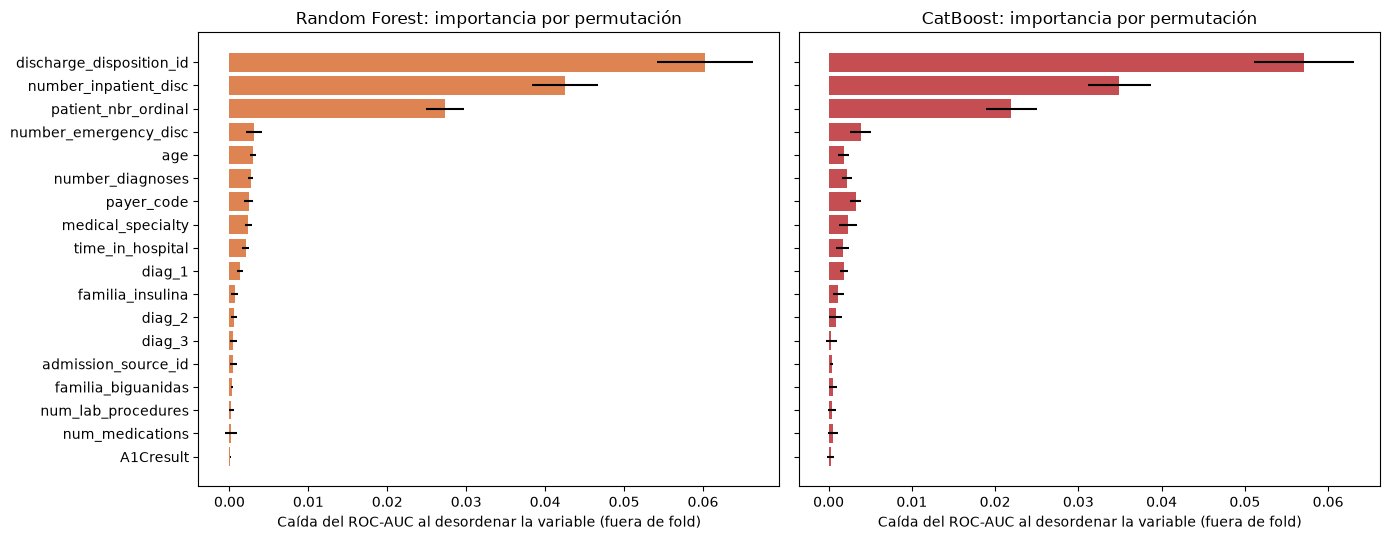

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
orden = tabla_imp.index[::-1]
for ax, nombre, color in zip(axes, ["Random Forest", "CatBoost"], ["#DD8452", "#C44E52"]):
    ax.barh(orden, tabla_imp.loc[orden, f"{nombre}: caída media de ROC-AUC"],
            xerr=tabla_imp.loc[orden, f"{nombre}: desvío entre folds"], color=color)
    ax.set_title(f"{nombre}: importancia por permutación")
    ax.set_xlabel("Caída del ROC-AUC al desordenar la variable (fuera de fold)")
plt.tight_layout()
plt.show()

**Lectura del gráfico.** Los dos modelos muestran la misma forma: tres barras claramente más largas que el
resto, cuyas barras de error (el desvío entre folds) no se solapan con las de las demás variables. Entre el
cuarto lugar y el último, las diferencias son de milésimas y quedan dentro del ruido entre folds.

In [7]:
# Regresión logística ganadora: coeficientes promedio de los 5 folds (columnas estandarizadas)
coefs = []
for k in range(N_FOLDS):
    m, _, _, _ = ajustar_fold("Regresión logística", k)
    coefs.append(m.coef_[0])
coefs = pd.DataFrame(coefs, columns=NOMBRES_COLS)
tabla_coef = pd.DataFrame({"coeficiente medio": coefs.mean(), "desvío entre folds": coefs.std()})
tabla_coef = tabla_coef.reindex(tabla_coef["coeficiente medio"].abs().sort_values(ascending=False).index)
print(f"Coeficientes distintos de cero: {(tabla_coef['coeficiente medio'].abs() > 1e-9).sum()} de {len(tabla_coef)} "
      f"(penalización {'Lasso' if CONFIG_GANADORA['Regresión logística']['l1_ratio'] == 1.0 else 'Ridge'}, "
      f"C = {CONFIG_GANADORA['Regresión logística']['C']:.3g})")
tabla_coef.head(12).round(4)

Coeficientes distintos de cero: 23 de 26 (penalización Lasso, C = 0.0101)


,coeficiente medio,desvío entre folds
discharge_disposition_id_te,0.2929,0.0079
number_inpatient_disc_ord,0.2593,0.0071
patient_nbr_ordinal_ord,0.1043,0.0112
number_emergency_disc_ord,0.0743,0.0059
medical_specialty_te,0.0647,0.0151
familia_insulina_No,-0.0369,0.0057
number_diagnoses,0.0303,0.0112
familia_insulina_Down,0.0238,0.0034
diag_1_te,0.0207,0.0105
A1Cresult_No medido,0.0153,0.0063


**Lectura de los coeficientes.** La regresión logística ganadora usa penalización Lasso (`C` = 0,0101) y
conserva 23 de los 26 coeficientes, de modo que la regularización casi no elimina variables. Los más grandes
son positivos (aumentan el riesgo) y son los mismos tres que dominan en los ensambles: el tipo de alta
codificado (0,293), las internaciones previas (0,259) y los encuentros previos (0,104), seguidos de las visitas
de urgencia (0,074) y la especialidad médica (0,065). Los demás coeficientes son menores o iguales a 0,04; el
único negativo del grupo, `familia_insulina_No` (−0,037), indica que no recibir insulina se asocia a menor riesgo.

### Errores por subgrupos

Se analizan las predicciones fuera de fold del modelo elegido (Random Forest) por grupos de pacientes que son
relevantes para el problema. En cada uno se informa el tamaño, la tasa de reingreso, el ROC-AUC y, con el
umbral de M6, el recall y la precisión. Un grupo con ROC-AUC muy distinto del global señala dónde el modelo
funciona peor.

In [8]:
modelo_sub = "Random Forest"
p_sub = OOF[modelo_sub]
u_sub = float(UMBRALES[int(np.argmax(curvas[modelo_sub]))])
bandas = {"[0-10)": "menores de 30", "[10-20)": "menores de 30", "[20-30)": "menores de 30",
          "[30-40)": "30 a 59", "[40-50)": "30 a 59", "[50-60)": "30 a 59",
          "[60-70)": "60 a 79", "[70-80)": "60 a 79", "[80-90)": "80 o más", "[90-100)": "80 o más"}
top_alta = X_train["discharge_disposition_id"].astype(object).value_counts().head(5).index
subgrupos = {
    "edad": X_train["age"].astype(object).map(bandas),
    "internaciones previas": X_train["number_inpatient_disc"].astype(object),
    "tipo de alta": X_train["discharge_disposition_id"].astype(object).where(
        X_train["discharge_disposition_id"].astype(object).isin(top_alta), "otros tipos de alta"),
    "sexo": X_train["gender"].astype(object),
}
filas = []
for grupo, serie in subgrupos.items():
    for nivel in sorted(serie.dropna().unique()):
        m = (serie == nivel).to_numpy()
        yy, pp = y_ent[m], p_sub[m]
        fila = {"grupo": grupo, "nivel": nivel if len(str(nivel)) < 45 else str(nivel)[:42] + "...",
                "pacientes-encuentros": int(m.sum()), "tasa de reingreso": float(yy.mean())}
        if yy.nunique() == 2:
            pred = (pp >= u_sub).astype(int)
            fila.update({"ROC-AUC": roc_auc_score(yy, pp), "recall": recall_score(yy, pred),
                         "precisión": precision_score(yy, pred, zero_division=0)})
        filas.append(fila)
tabla_sub = pd.DataFrame(filas).set_index(["grupo", "nivel"])
print(f"{modelo_sub}: umbral {u_sub:.2f}; ROC-AUC fuera de fold en todo train: {roc_auc_score(y_ent, p_sub):.4f}")
tabla_sub.round(3)

Random Forest: umbral 0.15; ROC-AUC fuera de fold en todo train: 0.6808


pacientes-encuentros  \
grupo                 nivel                                                                 
edad                  30 a 59                                                       21474   
                      60 a 79                                                       34164   
                      80 o más                                                      14124   
                      menores de 30                                                  1821   
internaciones previas 0                                                             47335   
                      1                                                             13777   
                      2                                                              5377   
                      3 o mas                                                        5094   
tipo de alta          Discharged to home                                            42343   
                      Discharged/transferred to SNF                                  9855   
                      Discharged/transferred to another short te...                  1537   
                      Discharged/transferred to home with home h...                  9038   
                      NULL                                                           2562   
                      otros tipos de alta                                            6248   
sexo                  Female                                                        38455   
                      Male                                                          33128   

                                                                     tasa de reingreso  \
grupo                 nivel                                                              
edad                  30 a 59                                                    0.100   
                      60 a 79                                                    0.117   
                      80 o más                                                   0.121   
                      menores de 30                                              0.125   
internaciones previas 0                                                          0.085   
                      1                                                          0.130   
                      2                                                          0.172   
                      3 o mas                                                    0.261   
tipo de alta          Discharged to home                                         0.093   
                      Discharged/transferred to SNF                              0.150   
                      Discharged/transferred to another short te...              0.160   
                      Discharged/transferred to home with home h...              0.134   
                      NULL                                                       0.122   
                      otros tipos de alta                                        0.139   
sexo                  Female                                                     0.113   
                      Male                                                       0.112   

                                                                     ROC-AUC  \
grupo                 nivel                                                    
edad                  30 a 59                                          0.706   
                      60 a 79                                          0.666   
                      80 o más                                         0.640   
                      menores de 30                                    0.791   
internaciones previas 0                                                0.650   
                      1                                                0.604   
                      2                                                0.577   
                      3 o mas                        

**Lectura de la tabla.** El ROC-AUC fuera de fold del Random Forest en todo el train es 0,681. Por subgrupos:
- **Edad:** el desempeño baja al aumentar la edad: 0,79 en menores de 30 (solo 1.821 encuentros, así que con
  más incertidumbre), 0,71 de 30 a 59, 0,67 de 60 a 79 y 0,64 desde los 80.
- **Internaciones previas:** dentro de cada nivel el modelo ordena peor (0,58 a 0,65) que en el conjunto. Buena
  parte del ROC-AUC global proviene de separar a los pacientes entre niveles, que es lo que ya hacía el basal.
- **Tipo de alta:** el desempeño va de 0,59 (alta a un centro de enfermería especializada) a 0,67 (alta a domicilio),
  y es de 0,77 en el conjunto de otros tipos de alta.
- **Sexo:** sin diferencias (0,68 en mujeres y en varones), con la misma tasa de reingreso (11,3 y 11,2 %).

Con un único umbral (0,15), el recall cambia mucho según el grupo: 0,18 en pacientes sin internaciones previas
y 0,995 en los que tienen tres o más, porque el modelo marca a casi todos los de alto historial y a pocos de
los demás.

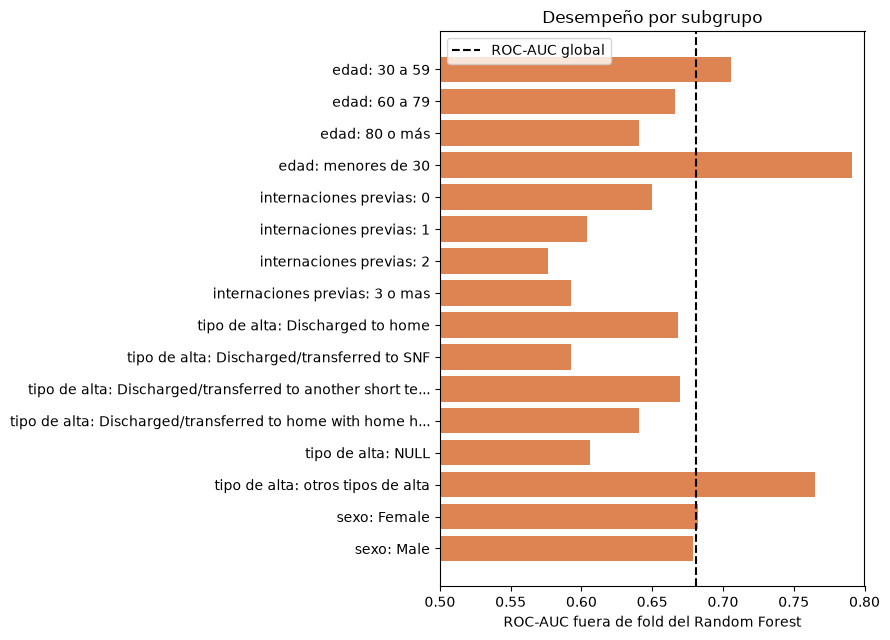

In [9]:
fig, ax = plt.subplots(figsize=(9, 6.5))
d = tabla_sub.reset_index()
etiquetas = [f"{g}: {n}" for g, n in zip(d["grupo"], d["nivel"])]
ax.barh(etiquetas[::-1], d["ROC-AUC"].to_numpy()[::-1], color="#DD8452")
ax.axvline(roc_auc_score(y_ent, p_sub), color="black", ls="--", label="ROC-AUC global")
ax.set_xlim(0.5, 0.8)
ax.set_xlabel("ROC-AUC fuera de fold del Random Forest")
ax.set_title("Desempeño por subgrupo")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura del gráfico.** Las barras muestran el mismo patrón: el modelo discrimina mejor en los pacientes más
jóvenes y peor dentro de los niveles de internaciones previas y del alta a centros de enfermería. Los grupos más
pequeños (menores de 30 y otros tipos de alta) son los más inciertos. No aparece un subgrupo con desempeño
cercano al azar (0,5).

### Perfiles de pacientes: una mirada no supervisada

Hasta acá el análisis fue supervisado: le dimos al modelo la respuesta y medimos cuánto acierta. Ahora hacemos la
pregunta al revés: ¿los pacientes se agrupan naturalmente en perfiles, sin mirar si reingresaron? Y si es así,
¿esos perfiles tienen riesgos distintos y el modelo funciona igual de bien en todos? Es una forma de conectar el
modelo con la realidad clínica y de ver si hay grupos de pacientes donde convendría trabajar por separado.

Usamos las herramientas de la clase 6:

1. **K-means** sobre las ocho variables numéricas y ordinales que describen al paciente y a su internación (edad,
   días internado, análisis, medicamentos, diagnósticos, internaciones y urgencias previas, encuentros previos),
   estandarizadas porque K-means es sensible a la escala. Dejamos afuera las variables con target encoding,
   porque llevan el reingreso adentro, y el identificador del paciente.
2. Para elegir la cantidad de grupos combinamos los tres criterios de la clase: el **método del codo**, el
   **índice de silueta** y la **fuerza de predicción** (Tibshirani y Walther, 2005), que mide si los grupos se
   mantienen al cambiar los datos. Siguiendo la clase, consideramos estable un agrupamiento con fuerza de
   predicción de 0,8 o más, y elegimos la mayor cantidad de grupos que cumple ese umbral.
3. Todo se calcula sobre el train. La silueta y la fuerza de predicción se calculan sobre muestras, porque su
   costo crece con el cuadrado de la cantidad de pacientes.

Cantidad de perfiles elegida: 4


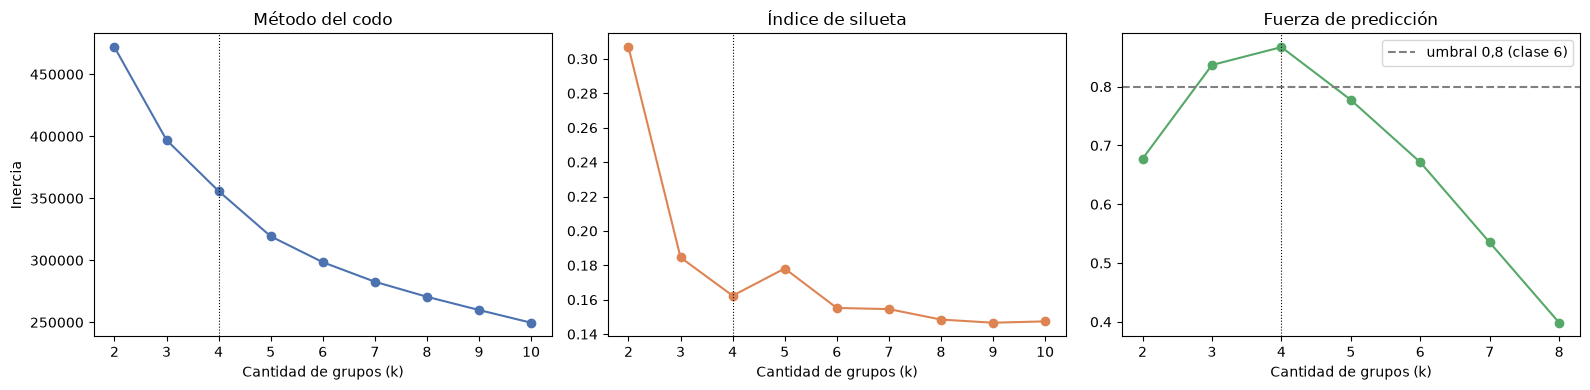

,inercia,silueta (muestra de 5.000),fuerza de predicción (media de 3)
k,,,
2,471898.107,0.307,0.677
3,396966.291,0.185,0.837
4,355807.030,0.162,0.867
5,319354.932,0.178,0.777
6,298458.732,0.155,0.671
7,282710.997,0.155,0.535
8,270589.238,0.148,0.399
9,259916.968,0.147,NaN
10,249667.080,0.147,NaN


In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

VARS_PERFIL = ["age", "time_in_hospital", "num_lab_procedures", "num_medications", "number_diagnoses",
               "number_inpatient_disc", "number_emergency_disc", "patient_nbr_ordinal"]
perfil = pd.DataFrame({v: (Xm_train[v].astype(object).map({nv: i for i, nv in enumerate(ORDENES[v])})
                           if v in ORDENES else Xm_train[v]).astype(float).to_numpy() for v in VARS_PERFIL})
assert not perfil.isna().any().any()
Z_perfil = StandardScaler().fit_transform(perfil)


def fuerza_prediccion(Z_a, Z_b, k, semilla):
    # Fuerza de predicción (Tibshirani y Walther, 2005), como en la notebook auxiliar de la clase 6: se agrupa Z_b
    # con su propio modelo y con el modelo entrenado en Z_a, y se mide qué proporción de los pares de cada grupo
    # sigue junta. Se informa el peor grupo.
    m_a = KMeans(n_clusters=k, n_init=10, random_state=semilla).fit(Z_a)
    m_b = KMeans(n_clusters=k, n_init=10, random_state=semilla).fit(Z_b)
    propio, ajeno = m_b.labels_, m_a.predict(Z_b)
    fuerzas = []
    for g in range(k):
        miembros = np.where(propio == g)[0]
        n = len(miembros)
        if n > 1:
            juntos = ajeno[miembros][:, None] == ajeno[miembros][None, :]
            fuerzas.append((juntos.sum() - n) / (n * (n - 1)))
    return min(fuerzas)


rng_clu = np.random.RandomState(SEMILLA)
muestra_sil = rng_clu.choice(len(Z_perfil), 5000, replace=False)
filas = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z_perfil)
    fila = {"k": k, "inercia": km.inertia_,
            "silueta (muestra de 5.000)": silhouette_score(Z_perfil[muestra_sil], km.labels_[muestra_sil])}
    if k <= 8:
        fp = []
        for rep in range(3):                                  # tres pares de mitades de 2.000 pacientes
            m = np.random.RandomState(SEMILLA + rep).choice(len(Z_perfil), 4000, replace=False)
            fp.append(fuerza_prediccion(Z_perfil[m[:2000]], Z_perfil[m[2000:]], k, SEMILLA + rep))
        fila["fuerza de predicción (media de 3)"] = np.mean(fp)
    filas.append(fila)
eleccion_k = pd.DataFrame(filas).set_index("k")
estables = eleccion_k.index[eleccion_k["fuerza de predicción (media de 3)"] >= 0.8]
K_PERFILES = int(estables.max()) if len(estables) else int(eleccion_k["silueta (muestra de 5.000)"].idxmax())
print(f"Cantidad de perfiles elegida: {K_PERFILES}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(eleccion_k.index, eleccion_k["inercia"], "o-", color="#4C72B0")
axes[0].set_title("Método del codo"); axes[0].set_xlabel("Cantidad de grupos (k)"); axes[0].set_ylabel("Inercia")
axes[1].plot(eleccion_k.index, eleccion_k["silueta (muestra de 5.000)"], "o-", color="#DD8452")
axes[1].set_title("Índice de silueta"); axes[1].set_xlabel("Cantidad de grupos (k)")
fp_serie = eleccion_k["fuerza de predicción (media de 3)"].dropna()
axes[2].plot(fp_serie.index, fp_serie, "o-", color="#55A868")
axes[2].axhline(0.8, color="gray", ls="--", label="umbral 0,8 (clase 6)")
axes[2].set_title("Fuerza de predicción"); axes[2].set_xlabel("Cantidad de grupos (k)"); axes[2].legend()
for ax in axes:
    ax.axvline(K_PERFILES, color="black", lw=0.8, ls=":")
plt.tight_layout()
plt.show()
eleccion_k.round(3)

**Lectura.** Los tres criterios no apuntan al mismo número, algo habitual con datos reales. El codo no muestra un
quiebre claro y la silueta es baja para cualquier cantidad de grupos (0,31 con dos y entre 0,15 y 0,19 desde
tres), lo que indica que los pacientes no forman grupos bien separados sino un continuo. La fuerza de predicción
es la que permite decidir: supera el umbral de 0,8 con tres y cuatro grupos (0,84 y 0,87) y cae por debajo desde
cinco. Siguiendo la regla declarada, nos quedamos con **cuatro perfiles**, la mayor cantidad de grupos que se
reproduce de manera estable al cambiar los pacientes. Con dos grupos la silueta es mejor, pero la partición no es
estable (fuerza de predicción de 0,68).

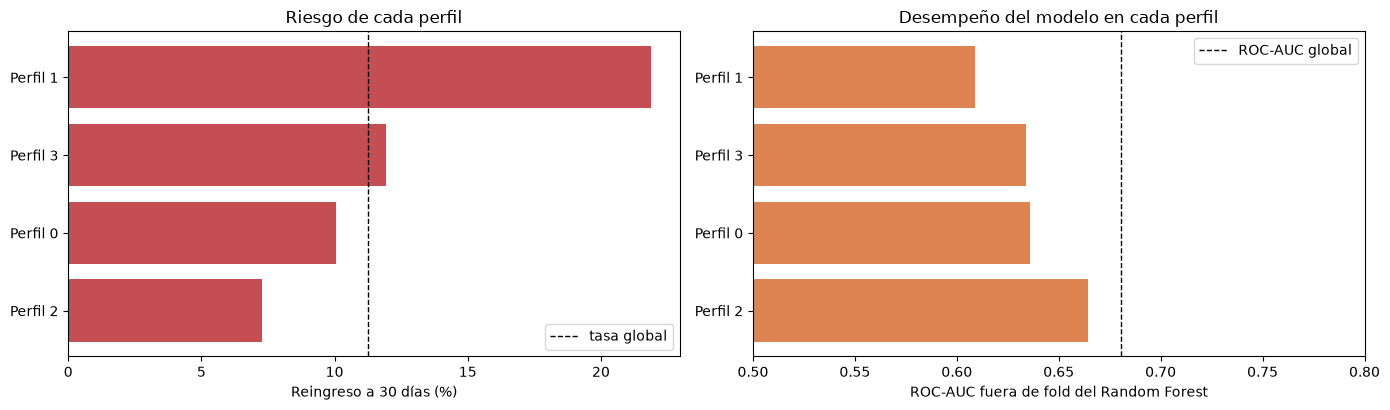

,internaciones (train),% del train,edad mediana,días internado (media),medicamentos (media),diagnósticos (media),% con internaciones previas,% con urgencias previas,tasa de reingreso (%),ROC-AUC del modelo,recall del modelo,precisión del modelo
perfil,,,,,,,,,,,,
2,18755,26.20,[50-60),2.92,11.81,4.91,17.46,5.71,7.27,0.66,0.19,0.23
0,27984,39.09,[70-80),3.24,13.75,8.43,25.08,8.19,10.05,0.64,0.22,0.20
3,15537,21.70,[60-70),8.14,24.55,8.29,31.13,8.01,11.93,0.63,0.37,0.20
1,9307,13.00,[60-70),4.53,16.90,8.02,97.97,37.27,21.87,0.61,0.92,0.23


In [11]:
km_perfil = KMeans(n_clusters=K_PERFILES, n_init=10, random_state=SEMILLA).fit(Z_perfil)
grupo = km_perfil.labels_
nombres_edad = list(ORDENES["age"])
filas = []
for g in range(K_PERFILES):
    m = grupo == g
    yy, pp = y_ent.to_numpy()[m], p_sub[m]
    pred = (pp >= u_sub).astype(int)
    filas.append({
        "perfil": g, "internaciones (train)": int(m.sum()), "% del train": m.mean() * 100,
        "edad mediana": nombres_edad[int(np.median(perfil.loc[m, "age"]))],
        "días internado (media)": perfil.loc[m, "time_in_hospital"].mean(),
        "medicamentos (media)": perfil.loc[m, "num_medications"].mean(),
        "diagnósticos (media)": perfil.loc[m, "number_diagnoses"].mean(),
        "% con internaciones previas": (perfil.loc[m, "number_inpatient_disc"] > 0).mean() * 100,
        "% con urgencias previas": (perfil.loc[m, "number_emergency_disc"] > 0).mean() * 100,
        "tasa de reingreso (%)": yy.mean() * 100,
        "ROC-AUC del modelo": roc_auc_score(yy, pp) if len(set(yy)) == 2 else np.nan,
        "recall del modelo": recall_score(yy, pred, zero_division=0),
        "precisión del modelo": precision_score(yy, pred, zero_division=0)})
tabla_perfiles = pd.DataFrame(filas).set_index("perfil").sort_values("tasa de reingreso (%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
etiquetas_p = [f"Perfil {g}" for g in tabla_perfiles.index]
axes[0].barh(etiquetas_p, tabla_perfiles["tasa de reingreso (%)"], color="#C44E52")
axes[0].axvline(y_ent.mean() * 100, color="black", ls="--", lw=1, label="tasa global")
axes[0].set_xlabel("Reingreso a 30 días (%)"); axes[0].set_title("Riesgo de cada perfil"); axes[0].legend()
axes[1].barh(etiquetas_p, tabla_perfiles["ROC-AUC del modelo"], color="#DD8452")
axes[1].axvline(roc_auc_score(y_ent, p_sub), color="black", ls="--", lw=1, label="ROC-AUC global")
axes[1].set_xlim(0.5, 0.8); axes[1].set_xlabel("ROC-AUC fuera de fold del Random Forest")
axes[1].set_title("Desempeño del modelo en cada perfil"); axes[1].legend()
plt.tight_layout()
plt.show()
tabla_perfiles.round(2)

**Lectura.** Los cuatro perfiles tienen una lectura clínica clara, y el riesgo se triplica de uno a otro:

| Perfil | Quiénes son | Reingreso |
|---|---|---|
| 2 (26 %) | Los más jóvenes (mediana de 50 a 60 años), con internaciones cortas (2,9 días), pocos medicamentos y pocos diagnósticos | 7,3 % |
| 0 (39 %) | Los mayores (mediana de 70 a 80 años), con internaciones cortas pero muchos diagnósticos | 10,1 % |
| 3 (22 %) | Internaciones largas (8,1 días) y complejas, con 25 medicamentos en promedio | 11,9 % |
| 1 (13 %) | Pacientes con historial: casi todos (98 %) tuvieron internaciones en el año previo y más de un tercio, urgencias | 21,9 % |

Sin conocer el reingreso, el agrupamiento volvió a encontrar lo que mostraron el EDA y la importancia de
variables: el historial del paciente es el eje que más separa el riesgo.

La segunda mirada es la más útil. Dentro de cada perfil el modelo ordena a los pacientes peor que en el conjunto
(ROC-AUC de 0,61 a 0,66, contra 0,68 global), y lo hace peor justamente en el perfil de mayor riesgo. En el
perfil 1 el modelo marca a casi todos (recall de 0,92) con una precisión de 0,23: en ese grupo funciona
prácticamente como la regla del basal, porque no logra distinguir cuáles de los pacientes con historial van a
reingresar. Esto le da sustento a una de las propuestas de "Nuevos caminos": entrenar un modelo específico para
los pacientes con historial, el grupo donde más se necesita discriminar. Una limitación: la silueta baja indica
que los límites entre perfiles son difusos, así que conviene leerlos como tendencias y no como categorías
cerradas.

## 8.9 M9: Evaluación final en el test

Es la **única** vez que se usa el test. Antes de abrirlo quedan congelados: las 18 variables y el
preprocesamiento (se ajusta con todo el train), los hiperparámetros ganadores de M5, los umbrales de M6 (elegidos
con predicciones fuera de fold del train), el basal y la regla de elección de M7, que señala a Random Forest. Los
cuatro algoritmos y el basal se evalúan una vez, con esas configuraciones, y no se vuelve a iterar sobre
el modelo mirando estos resultados.

Cada algoritmo se reentrena con **todo el train**. En XGBoost y CatBoost no hay un conjunto apartado para el early
stopping, así que la cantidad de árboles se toma del promedio de los 5 folds de M6 y se multiplica por 1,25,
porque el modelo final ve unas 1,25 veces más datos que el de cada fold.

Las métricas se informan con **intervalo de confianza del 95 %** por *bootstrap*. Se
remuestrean **pacientes**, no filas, porque las internaciones de un mismo paciente están correlacionadas y un
bootstrap por fila daría intervalos demasiado angostos. Con 1.000 réplicas se calcula también la mejora de cada
algoritmo sobre el basal.

In [12]:
# --- Abrir el test (única vez) ---
sellado = pd.read_pickle(ARTEFACTOS / "test_sellado.pkl")
Xm_test, y_test = sellado["X"], np.asarray(sellado["y"])
grupos_test = np.asarray(sellado["grupos"])
print(f"Test: {len(y_test)} filas, {len(set(grupos_test))} pacientes, tasa de reingreso {y_test.mean():.4f}")

# --- Preprocesamiento ajustado con TODO el train (target encoding fuera de fold para las filas de train) ---
prep_final = preprocesamiento()
Z_tr = prep_final.fit_transform(Xm_train, y_ent)
Z_te = prep_final.transform(Xm_test)
assert Z_tr.shape[1] == Z_te.shape[1] == 26

# --- Cantidad de árboles de los boosting: promedio de M6 por 1,25 ---
N_ARBOLES = {n: int(round(np.mean(ARBOLES[n]) * 1.25)) for n in ["XGBoost", "CatBoost"]}


def modelo_final(nombre):
    p = CONFIG_GANADORA[nombre]
    if nombre == "XGBoost":
        return XGBClassifier(n_estimators=N_ARBOLES[nombre], tree_method="hist", n_jobs=-1, random_state=SEMILLA, **p)
    if nombre == "CatBoost":
        return CatBoostClassifier(iterations=N_ARBOLES[nombre], random_seed=SEMILLA, verbose=0, thread_count=-1, **p)
    return construir(nombre, p, SEMILLA)


MODELOS_FINALES, p_test = {}, {}
for nombre in ALGORITMOS:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        MODELOS_FINALES[nombre] = modelo_final(nombre).fit(Z_tr, y_ent.to_numpy())
    p_test[nombre] = MODELOS_FINALES[nombre].predict_proba(Z_te)[:, 1]

# --- Basal: regla de M1 con el corte calculado sobre todo el train (internaciones previas >= k_final) ---
p_test["Basal"], _ = aplicar_regla(Xm_test[VAR_BASAL], k_final)      # puntaje: el nivel (0 a 3)
p_test["Basal"] = p_test["Basal"].astype(float)

UMBRAL_FINAL = {n: float(UMBRALES[int(np.argmax(curvas[n]))]) for n in ALGORITMOS}
UMBRAL_FINAL["Basal"] = float(k_final)                                 # la regla: nivel >= k_final
pred_test = {n: (p_test[n] >= UMBRAL_FINAL[n]).astype(int) for n in MODELOS}
print("Árboles finales:", N_ARBOLES, "| umbrales:", {k: round(v, 3) for k, v in UMBRAL_FINAL.items()})

Test: 30180 filas, 21455 pacientes, tasa de reingreso 0.1091
Árboles finales: {'XGBoost': 244, 'CatBoost': 549} | umbrales: {'Regresión logística': 0.13, 'Random Forest': 0.15, 'XGBoost': 0.145, 'CatBoost': 0.145, 'Basal': 1.0}


In [13]:
# --- Bootstrap por paciente: cada réplica remuestrea pacientes y pondera sus filas ---
codigo_pac, _ = pd.factorize(grupos_test)
n_pac = codigo_pac.max() + 1
rng = np.random.RandomState(SEMILLA)
N_BOOT = 1000
NOMBRES_MET = ["ROC-AUC", "AUC-PR", "recall", "precisión", "F1", "exactitud balanceada"]


def met_pesadas(y, p, pred, w):
    tp = np.sum(w * ((pred == 1) & (y == 1))); fn = np.sum(w * ((pred == 0) & (y == 1)))
    fp = np.sum(w * ((pred == 1) & (y == 0))); tn = np.sum(w * ((pred == 0) & (y == 0)))
    rec = tp / (tp + fn) if tp + fn else 0.0
    pre = tp / (tp + fp) if tp + fp else 0.0
    return {"ROC-AUC": roc_auc_score(y, p, sample_weight=w), "AUC-PR": average_precision_score(y, p, sample_weight=w),
            "recall": rec, "precisión": pre, "F1": 2 * pre * rec / (pre + rec) if pre + rec else 0.0,
            "exactitud balanceada": (rec + tn / (tn + fp)) / 2}


puntual = {n: met_pesadas(y_test, p_test[n], pred_test[n], np.ones(len(y_test))) for n in MODELOS}
boot = {n: [] for n in MODELOS}
for _ in range(N_BOOT):
    cuenta = np.bincount(rng.randint(0, n_pac, n_pac), minlength=n_pac)
    w = cuenta[codigo_pac].astype(float)
    for n in MODELOS:
        boot[n].append(met_pesadas(y_test, p_test[n], pred_test[n], w))
boot = {n: pd.DataFrame(b) for n, b in boot.items()}

filas = {}
for n in MODELOS:
    filas[n] = {c: f"{puntual[n][c]:.3f} [{boot[n][c].quantile(0.025):.3f}; {boot[n][c].quantile(0.975):.3f}]"
                for c in NOMBRES_MET}
tabla_test = pd.DataFrame(filas).T.loc[["Basal"] + ALGORITMOS]
for n in MODELOS:
    registrar(fase="M9", algoritmo=n, **{c: puntual[n][c] for c in NOMBRES_MET})
guardar_registro()
tabla_test

,ROC-AUC,AUC-PR,recall,precisión,F1,exactitud balanceada
Basal,0.603 [0.592; 0.613],0.153 [0.144; 0.163],0.488 [0.468; 0.507],0.162 [0.153; 0.170],0.244 [0.231; 0.254],0.590 [0.580; 0.600]
Regresión logística,0.665 [0.654; 0.676],0.201 [0.189; 0.215],0.427 [0.407; 0.446],0.201 [0.191; 0.211],0.274 [0.260; 0.287],0.610 [0.600; 0.620]
Random Forest,0.677 [0.666; 0.687],0.211 [0.199; 0.224],0.405 [0.385; 0.425],0.214 [0.203; 0.225],0.280 [0.266; 0.293],0.612 [0.602; 0.621]
XGBoost,0.679 [0.668; 0.689],0.218 [0.205; 0.232],0.445 [0.425; 0.464],0.205 [0.194; 0.215],0.281 [0.267; 0.294],0.617 [0.608; 0.626]
CatBoost,0.680 [0.669; 0.690],0.220 [0.206; 0.233],0.425 [0.404; 0.445],0.210 [0.199; 0.220],0.281 [0.267; 0.294],0.614 [0.605; 0.624]


**Lectura de la tabla.** En el test, evaluado una sola vez, los cuatro algoritmos superan al basal en el
ROC-AUC y en el AUC-PR: 0,665 la regresión logística, 0,677 Random Forest (el modelo que eligió la regla de M7),
0,679 XGBoost y 0,680 CatBoost, contra 0,603 del basal. Son entre 0,002 y 0,005 menos que en la validación
cruzada (0,6705, 0,6811, 0,6811 y 0,6828), una diferencia que cae dentro de los intervalos de confianza. Los
intervalos de los tres ensambles se superponen casi por completo ([0,666; 0,687], [0,668; 0,689] y [0,669;
0,690]), de modo que el test tampoco los distingue entre sí; la regresión logística (0,665) queda por debajo, y
en la validación cruzada esa diferencia sí fue significativa. Con los umbrales fijados en M6, el F1 va de 0,274 a
0,281 (basal 0,244), la precisión de 0,20 a 0,21 (basal 0,162), el recall de 0,41 a 0,45 (basal 0,488) y la
exactitud balanceada de 0,610 a 0,617 (basal 0,590): los algoritmos ganan precisión y F1 a costa de algo de
recall, igual que en la validación cruzada. El AUC-PR sube de 0,153 a entre 0,201 y 0,220, con una prevalencia
de 0,109 en el test.

In [14]:
# Mejora de cada algoritmo sobre el basal (diferencia con el mismo remuestreo de pacientes)
filas = []
for n in ALGORITMOS:
    for c in ["ROC-AUC", "AUC-PR", "F1"]:
        d = boot[n][c] - boot["Basal"][c]
        filas.append({"algoritmo": n, "métrica": c, "mejora sobre el basal": puntual[n][c] - puntual["Basal"][c],
                      "IC 95 % inferior": d.quantile(0.025), "IC 95 % superior": d.quantile(0.975)})
mejora_test = pd.DataFrame(filas).set_index(["algoritmo", "métrica"])
mejora_test.round(4)

mejora sobre el basal  IC 95 % inferior  \
algoritmo           métrica                                            
Regresión logística ROC-AUC                 0.0625            0.0548   
                    AUC-PR                  0.0478            0.0408   
                    F1                      0.0298            0.0214   
Random Forest       ROC-AUC                 0.0745            0.0662   
                    AUC-PR                  0.0581            0.0508   
                    F1                      0.0365            0.0266   
XGBoost             ROC-AUC                 0.0761            0.0675   
                    AUC-PR                  0.0649            0.0565   
                    F1                      0.0372            0.0282   
CatBoost            ROC-AUC                 0.0774            0.0692   
                    AUC-PR                  0.0663            0.0577   
                    F1                      0.0373            0.0279   

                             IC 95 % superior  
algoritmo           métrica                    
Regresión logística ROC-AUC            0.0702  
                    AUC-PR             0.0565  
                    F1                 0.0381  
Random Forest       ROC-AUC            0.0828  
                    AUC-PR             0.0654  
                    F1                 0.0461  
XGBoost             ROC-AUC            0.0847  
                    AUC-PR             0.0736  
                    F1                 0.0463  
CatBoost            ROC-AUC            0.0862  
                    AUC-PR             0.0749  
                    F1                 0.0461

**Lectura de la mejora sobre el basal.** La mejora de cada algoritmo es significativa, porque los intervalos
del 95 % de la diferencia no incluyen el cero: en ROC-AUC, +0,063 la regresión logística [0,055; 0,070], +0,075
Random Forest [0,066; 0,083], +0,076 XGBoost [0,068; 0,085] y +0,077 CatBoost [0,069; 0,086]; en AUC-PR,
entre +0,048 y +0,066; y en F1, entre +0,030 y +0,037. En términos absolutos la mejora es modesta: el mejor
modelo ordena correctamente alrededor del 68 % de los pares formados por un paciente que reingresa y otro que
no, contra el 60 % del basal.

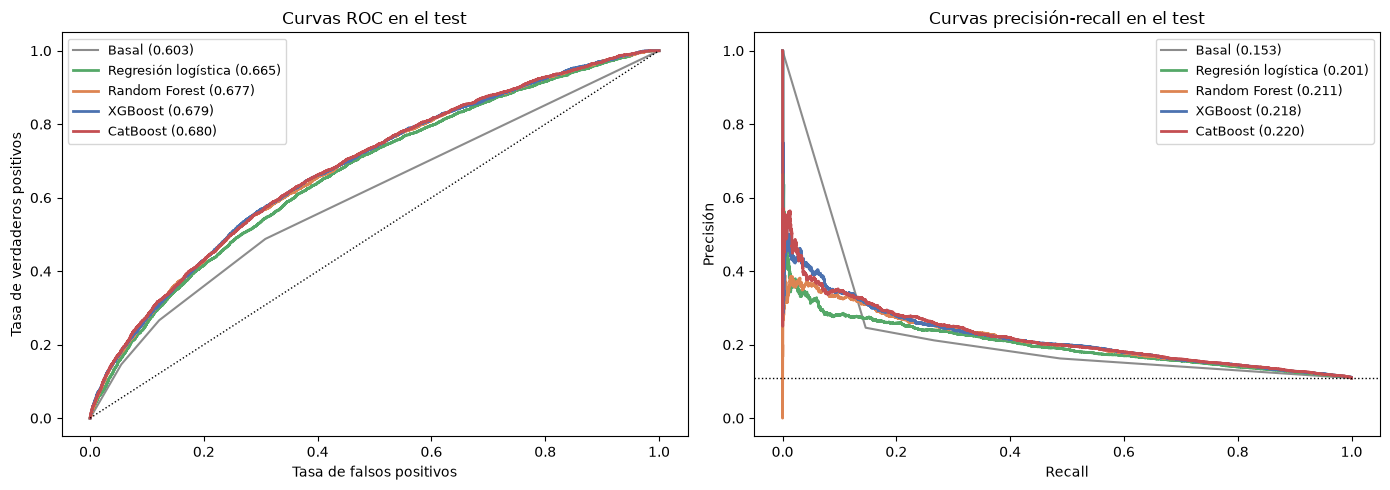

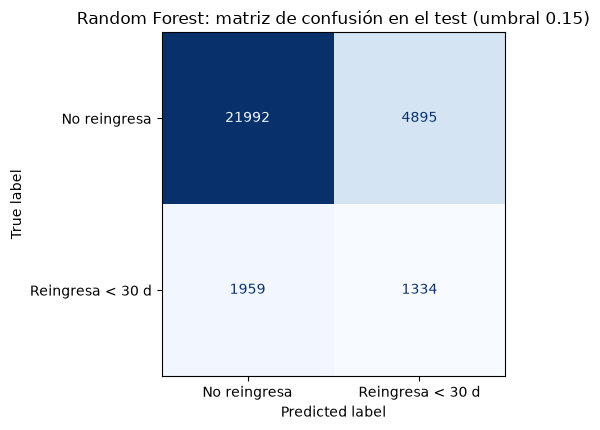

Verdaderos negativos 21992, falsos positivos 4895, falsos negativos 1959, verdaderos positivos 1334


In [15]:
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
colores_m = {"Basal": "#8C8C8C", "Regresión logística": "#55A868", "Random Forest": "#DD8452",
             "XGBoost": "#4C72B0", "CatBoost": "#C44E52"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for n in MODELOS:
    fpr, tpr, _ = roc_curve(y_test, p_test[n])
    axes[0].plot(fpr, tpr, label=f"{n} ({puntual[n]['ROC-AUC']:.3f})", color=colores_m[n], lw=2 if n != "Basal" else 1.5)
    pre, rec, _ = precision_recall_curve(y_test, p_test[n])
    axes[1].plot(rec, pre, label=f"{n} ({puntual[n]['AUC-PR']:.3f})", color=colores_m[n], lw=2 if n != "Basal" else 1.5)
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].set_title("Curvas ROC en el test")
axes[1].axhline(y_test.mean(), color="black", ls=":", lw=1)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisión")
axes[1].set_title("Curvas precisión-recall en el test")
for ax in axes:
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 4.4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test[elegido]),
                       display_labels=["No reingresa", "Reingresa < 30 d"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"{elegido}: matriz de confusión en el test (umbral {UMBRAL_FINAL[elegido]:.2f})")
plt.tight_layout()
plt.show()
cm = confusion_matrix(y_test, pred_test[elegido])
print(f"Verdaderos negativos {cm[0,0]}, falsos positivos {cm[0,1]}, falsos negativos {cm[1,0]}, verdaderos positivos {cm[1,1]}")

**Lectura de los gráficos.** Las curvas ROC de los tres ensambles son prácticamente indistinguibles, la de la
regresión logística queda algo por debajo en la zona media, y todas están por encima del basal, cuya curva solo
tiene cuatro tramos porque su puntaje toma cuatro valores. En las curvas de precisión-recall los cuatro modelos
superan la prevalencia (línea punteada, 0,109) y se parecen entre sí: la precisión cae rápido al exigir más
recall, y con un recall cercano a 0,4 es de alrededor de 0,2 en todos. La matriz de confusión del Random Forest
con el umbral 0,15 muestra que identifica 1.334 de los 3.293 reingresos (recall 0,405) y marca a 4.895 pacientes
que no reingresan, de 26.887 (18 %). En total marca al 21 % de los pacientes y, de cada 100 marcados, 21
reingresan (precisión 0,214), casi el doble de la tasa de la población (10,9 %).

### Qué significa en la práctica

Las métricas se entienden mejor traducidas a lo que vería un hospital que usa la regla o el modelo para decidir a
quién hacerle un seguimiento después del alta. La tabla lleva los resultados del test a una escala de 1.000
altas. Agregamos una comparación que nos parece la más justa: el modelo marcando **la misma cantidad de
pacientes que la regla del basal**, es decir, con la misma carga de trabajo para el equipo de seguimiento.

In [16]:
def resumen_criterio(pred, y):
    marcados, vp = pred.sum(), ((pred == 1) & (y == 1)).sum()
    escala = 1000 / len(y)
    return {"pacientes a seguir": marcados * escala, "reingresos detectados": vp * escala,
            "falsas alarmas": (marcados - vp) * escala, "reingresos sin detectar": ((pred == 0) & (y == 1)).sum() * escala,
            "pacientes a seguir por cada reingreso detectado": marcados / vp}


n_basal = int(pred_test["Basal"].sum())
pred_misma_carga = np.zeros(len(y_test), dtype=int)
pred_misma_carga[np.argsort(-p_test[elegido])[:n_basal]] = 1
impacto = pd.DataFrame({
    "Regla del basal (al menos una internación previa)": resumen_criterio(pred_test["Basal"], y_test),
    f"{elegido} con su umbral": resumen_criterio(pred_test[elegido], y_test),
    f"{elegido} con la misma carga que el basal": resumen_criterio(pred_misma_carga, y_test),
    "Seguimiento al azar con la misma carga que el basal": {
        "pacientes a seguir": n_basal / len(y_test) * 1000,
        "reingresos detectados": n_basal / len(y_test) * 1000 * y_test.mean(),
        "falsas alarmas": n_basal / len(y_test) * 1000 * (1 - y_test.mean()),
        "reingresos sin detectar": (1 - n_basal / len(y_test)) * 1000 * y_test.mean(),
        "pacientes a seguir por cada reingreso detectado": 1 / y_test.mean()},
}).T
impacto.round(1)

,pacientes a seguir,reingresos detectados,falsas alarmas,reingresos sin detectar,pacientes a seguir por cada reingreso detectado
Regla del basal (al menos una internación previa),327.6,53.2,274.4,55.9,6.2
Random Forest con su umbral,206.4,44.2,162.2,64.9,4.7
Random Forest con la misma carga que el basal,327.6,61.2,266.5,47.9,5.4
Seguimiento al azar con la misma carga que el basal,327.6,35.7,291.9,73.4,9.2


**Lectura.** Por cada 1.000 altas, la regla del basal manda a seguimiento a 328 pacientes y detecta 53 de los
alrededor de 109 reingresos: hay que seguir a 6 pacientes para encontrar uno que reingresa. Seguir a la misma
cantidad de pacientes elegidos al azar detectaría solo 36. El modelo con su umbral marca menos pacientes (unos
206) y detecta algo menos de reingresos, pero es más eficiente: alrededor de 5 pacientes seguidos por cada
reingreso encontrado.

La comparación más clara es con la misma carga de trabajo. Si el equipo puede seguir a 328 pacientes de cada
1.000, como con la regla, elegirlos con el modelo detecta 61 reingresos en lugar de 53: 8 reingresos más cada
1.000 altas, un 15 % más, sin agregar un solo seguimiento. Esa es, en términos concretos, la ganancia del modelo
sobre la regla simple. También muestra cómo convendría elegir el umbral en un uso real: según cuántos pacientes
puede seguir el equipo, que es el punto de operación que no pudimos definir en M2 por falta de información sobre
costos.

### Calibración en el test

En 8.6.1 (notebook 3) elegimos, con el train, el método de calibración con menor ECE para cada algoritmo, y
ajustamos el calibrador con las predicciones fuera de fold. Acá lo aplicamos por única vez al test del modelo
elegido. La calibración no cambia a quién se marca con el umbral de M6: solo cambia qué tan creíble es la
probabilidad que se informa.

Random Forest, método elegido con el train: Isotónica | tasa real del test: 0.1091 | Brier de predecir la tasa base del train: 0.0972


,Brier,ECE,ROC-AUC,probabilidad media,probabilidad máxima
Sin calibrar,0.0928,0.0034,0.6773,0.1096,0.4906
Isotónica (ajustada en train),0.0928,0.0030,0.6772,0.1106,0.5758


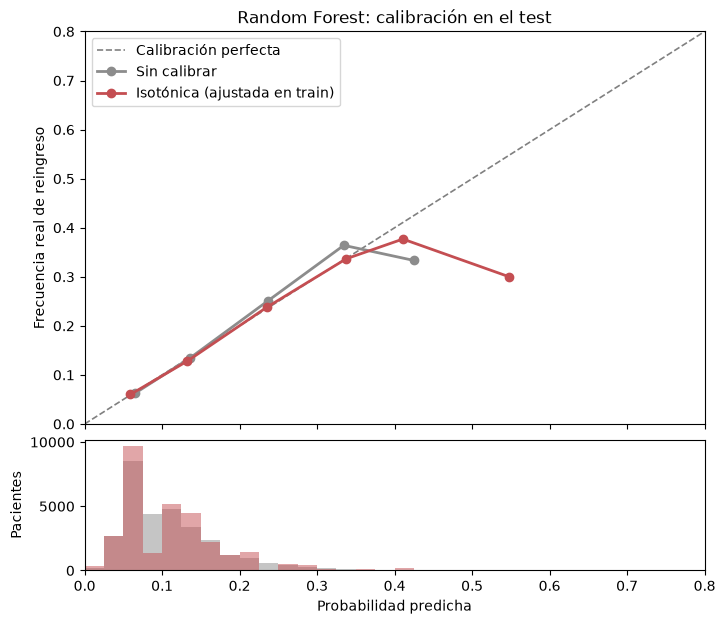

In [17]:
metodo_cal = tabla_cal.loc[elegido, "ECE"].drop("Sin calibrar").idxmin()     # decidido con el train, no con el test
p_test_cal = aplicar_calibrador(CALIBRADORES[elegido][metodo_cal], p_test[elegido], metodo_cal)
versiones = {"Sin calibrar": p_test[elegido], f"{metodo_cal} (ajustada en train)": p_test_cal}
cal_test = pd.DataFrame({v: {"Brier": brier_score_loss(y_test, p), "ECE": ece(y_test, p), "ROC-AUC": roc_auc_score(y_test, p),
                             "probabilidad media": p.mean(), "probabilidad máxima": p.max()}
                         for v, p in versiones.items()}).T
print(f"{elegido}, método elegido con el train: {metodo_cal} | tasa real del test: {y_test.mean():.4f} | "
      f"Brier de predecir la tasa base del train: {brier_score_loss(y_test, np.full(len(y_test), y_ent.mean())):.4f}")
display(cal_test.round(4))

fig, (ax, ax_h) = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1], "hspace": 0.06})
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1.2, label="Calibración perfecta")
for (v, p), color in zip(versiones.items(), ["#8C8C8C", "#C44E52"]):
    frac, media = calibration_curve(y_test, p, n_bins=10)
    ax.plot(media, frac, "o-", lw=2, color=color, label=v)
    ax_h.hist(p, bins=np.linspace(0, 1, 41), color=color, alpha=0.5)
ax.set_xlim(0, 0.8); ax.set_ylim(0, 0.8)
ax.set_ylabel("Frecuencia real de reingreso"); ax.set_title(f"{elegido}: calibración en el test"); ax.legend()
ax_h.set_xlabel("Probabilidad predicha"); ax_h.set_ylabel("Pacientes")
plt.show()

**Lectura.** En el test, el Random Forest también está bien calibrado sin corrección: hasta 0,3, donde está casi
toda la población, la curva sigue la diagonal, y la probabilidad media (0,110) coincide con la tasa real del test
(0,109). El ECE es bajo (0,0034) y la regresión isotónica, el método elegido con el train, lo baja apenas (0,0030)
sin cambiar el Brier ni el ROC-AUC. Por encima de 0,3 hay muy pocos pacientes y los puntos no son confiables.
Frente a predecir siempre la tasa base (Brier 0,097), el modelo mejora poco (0,093), coherente con una
discriminación modesta. En la práctica, cuando el modelo asigna por ejemplo un 25 % de riesgo, alrededor de uno
de cada cuatro de esos pacientes efectivamente reingresa, y esa cifra se puede comunicar al equipo médico tal
como sale.

In [18]:
# Artefactos: pipelines finales ajustados (preprocesamiento + modelos) y resultados del test
import joblib
joblib.dump({"preprocesamiento": prep_final, "modelos": MODELOS_FINALES, "umbrales": UMBRAL_FINAL,
             "arboles": N_ARBOLES, "elegido": elegido}, ARTEFACTOS / "pipelines_finales.joblib", compress=3)
pd.DataFrame(puntual).T.to_csv(ARTEFACTOS / "m9_resultados_test.csv")
pd.DataFrame([{"modelo": n, "metrica": c, "estimacion": puntual[n][c], "ic_inferior": boot[n][c].quantile(0.025),
               "ic_superior": boot[n][c].quantile(0.975)} for n in MODELOS for c in NOMBRES_MET]
             ).to_csv(ARTEFACTOS / "m9_resultados_test_ic.csv", index=False)
mejora_test.to_csv(ARTEFACTOS / "m9_mejora_sobre_basal.csv")
(ARTEFACTOS / "m9_matriz_confusion.json").write_text(json.dumps(
    {"modelo": elegido, "umbral": UMBRAL_FINAL[elegido], "matriz": confusion_matrix(y_test, pred_test[elegido]).tolist()}))
print("Guardado: pipelines_finales.joblib y los resultados del test en artefactos_ml/")

Guardado: pipelines_finales.joblib y los resultados del test en artefactos_ml/


## 8.10 M10: Limitaciones, reflexión y reproducibilidad

### Resultado

Con las 18 variables del EDA, los cuatro algoritmos superan al basal. En el test, evaluado una sola vez, el
ROC-AUC va de 0,665 (regresión logística) a 0,680 (CatBoost), contra 0,603 del basal, es decir una mejora de
0,063 a 0,077 con intervalos del 95 % que excluyen el cero. Los tres ensambles (Random Forest, XGBoost y
CatBoost) no se distinguen entre sí ni en la validación cruzada ni en el test, y superan a la regresión logística
por unas 0,011 en la validación cruzada. La regla de elección declarada de antemano señala a Random Forest como
modelo final por parsimonia (ROC-AUC 0,677 en el test), pero CatBoost y XGBoost serían igualmente defendibles. Con
el umbral elegido sin mirar el test, los algoritmos ganan entre 0,04 y 0,05 de precisión y de 0,03 a 0,04 de F1
frente al basal, a costa de 0,04 a 0,08 de recall. Se cumple el criterio de éxito de M2 (notebook 2): la mejora supera el desvío entre
folds, aunque la mejora en términos absolutos es modesta. Las probabilidades del modelo elegido están bien calibradas
en el test, y el análisis de perfiles muestra que el modelo discrimina peor dentro de cada grupo de pacientes que
en el conjunto.

### Por qué el desempeño es acotado: hipótesis

Los cuatro algoritmos, de tres familias distintas y con hiperparámetros ajustados por tres mecanismos, llegan a la
misma meseta de ROC-AUC (entre 0,67 y 0,68), y el ajuste de hiperparámetros apenas movió el resultado (+0,008 en
CatBoost, +0,0001 en la regresión logística). Cuando todos los modelos convergen al mismo valor, lo más probable es
que el límite lo ponga la información disponible y no el algoritmo: si después de probar varios modelos y
búsquedas la ganancia sobre el basal es chica, el problema probablemente es de datos. Las causas
posibles son que el reingreso dependa de factores ausentes en el registro (adherencia al tratamiento, apoyo social,
seguimiento ambulatorio posterior), que el diagnóstico venga agrupado por capítulo y no por código, que los
resultados de glucosa y de hemoglobina glicosilada falten en su mayoría, y que se mezclen 130 instituciones con
prácticas distintas.
Son hipótesis y no se verificaron en este trabajo.

### Limitaciones

- **Selección de variables fuera de los folds.** Las 18 variables se eligieron con todo el entrenamiento. El chequeo
  de la sección 8.3.1 (notebook 2) muestra que cinco variables marginales cambian de decisión según la muestra, y ninguna es
  importante, de modo que el efecto sobre la validación se considera menor.
- **Validación cruzada sin anidar.** El puntaje de una carrera es optimista; al reevaluar a los ganadores con folds
  de otras semillas el optimismo fue de 0,000 a −0,001.
- **Costo de los errores no cuantificado.** No se definió un punto de operación; las métricas secundarias usan un
  umbral técnico (el que maximiza el F1) y no uno basado en costos o en capacidad de seguimiento. La tabla de
  impacto de M9 muestra cómo se elegiría en la práctica.
- **Un solo conjunto de datos.** Los datos son de 1999 a 2008 y no incluyen el hospital, de modo que no se evaluó la
  validez externa por institución ni a períodos posteriores. La partición agrupa por paciente, pero no por hospital.
- **Historial del paciente.** `patient_nbr_ordinal` supone que el registro contiene todas las internaciones previas del paciente.

### Nuevos caminos

- Sumar información que el registro no tiene: códigos de diagnóstico completos en lugar de capítulos, resultados
  de laboratorio, comorbilidades y el tiempo transcurrido desde el alta anterior.
- Modelar por separado a los pacientes con historial de internaciones (el perfil 1 de M8), que tienen el
  mayor riesgo y donde el modelo menos discrimina.
- Fijar el punto de operación según la cantidad de pacientes que el equipo de salud puede seguir, como en la
  tabla de impacto de M9. Como las probabilidades ya están calibradas, también podrían usarse en un cálculo de
  costos si se contara con ellos.
- Validar por hospital y por período para medir la validez externa.
- Agregar interpretabilidad local por paciente.

### Reproducibilidad

Los cuatro notebooks se ejecutan en orden, cada uno a continuación del anterior: al final de los notebooks 1, 2
y 3 se guarda el estado de la sesión, que el siguiente carga al empezar. El entorno usado es Python 3.13,
scikit-learn 1.9.1, XGBoost 3.4.1, CatBoost 1.2.10 y Optuna 5.0.0 (el detalle completo está en
`artefactos_ml/versiones.csv` y en `requirements.txt`). Para guardar y cargar el estado entre notebooks se usa
la librería `dill`. Las semillas son 42 (global, split, carrera principal), 42 a 45 (folds) y 43 y 44
(repeticiones de la carrera). En la carpeta `artefactos_ml` quedan los índices del split y de los folds, la
configuración y los espacios de búsqueda, los resultados de las carreras (`m5_carrera_semilla*.pkl`, que el
notebook reutiliza si existen en lugar de recalcularlas; cada carrera tarda alrededor de una hora en 14 núcleos),
el registro de todos los experimentos (`registro_experimentos.csv`), los umbrales, los pipelines finales
serializados y los resultados del test. El test se guarda sellado (`test_sellado.pkl`) al principio del notebook 2 y solo se abre en 8.9, en este notebook.

**Nota sobre versiones y equipos.** Los resultados pueden variar levemente si los notebooks se corren con otras
versiones de las librerías, otro sistema operativo u otro procesador, porque cambian detalles internos de los
algoritmos (por ejemplo, cómo XGBoost y CatBoost reparten el cálculo entre núcleos) y el redondeo de las
operaciones. Lo comprobamos al correr el trabajo en dos computadoras distintas con las mismas versiones: el ROC-AUC
cambió recién en la cuarta cifra decimal, y las cantidades que dependen del umbral, como los pacientes marcados
cada 1.000 altas, cambiaron algo más, porque un corrimiento mínimo en las probabilidades alcanza para que un
paciente cercano al umbral cambie de lado. Las conclusiones fueron las mismas. Para reproducir los números exactos
recomendamos usar las versiones de `requirements.txt`. Los resultados de la búsqueda de hiperparámetros se cargan
desde `artefactos_ml` en lugar de recalcularse, así que los modelos ganadores son los mismos en cualquier equipo.

---
## Cierre del trabajo: respuesta a las preguntas de la investigación

Al principio del notebook 1 nos planteamos tres preguntas. Con todo el recorrido hecho, estas son nuestras
respuestas.

### 1. ¿Qué información del paciente y de la internación se asocia más con el reingreso temprano?

**El historial de internaciones del paciente y la forma en que deja el hospital.** Tres variables se destacan, y
lo hacen de manera consistente por cuatro caminos independientes:

| Variable | EDA (notebook 1) | Random Forest (permutación) | CatBoost (permutación) | Regresión logística (coeficiente) |
|---|---|---|---|---|
| Tipo de alta (`discharge_disposition_id`) | La de mayor asociación con el target original (sección 3.6) | 0,060 | 0,057 | 0,293 |
| Internaciones previas en el último año | La más relevante en la selección (V de Cramér 0,155, sección 6.1) | 0,043 | 0,035 | 0,259 |
| Encuentros previos del paciente en el registro | Junto con la anterior, encabeza la selección (sección 6.1) | 0,027 | 0,022 | 0,104 |

Las otras 15 variables aportan menos de 0,005 cada una en la importancia por permutación. Que el análisis
exploratorio, dos ensambles con lógicas distintas y un modelo lineal coincidan en las mismas tres variables, y en
el mismo orden, nos da confianza en que la señal es real y no un artefacto de un modelo en particular. El
análisis no supervisado lo confirma por un quinto camino: sin conocer el reingreso, K-means separa un perfil de
pacientes con historial de internaciones (13 % del train) cuyo riesgo triplica al del perfil de menor riesgo.

Las tres tienen una lectura clínica coherente. Las internaciones y los encuentros previos describen a un paciente
con una enfermedad más avanzada o más difícil de controlar. El tipo de alta resume cómo sale del hospital: no es
lo mismo volver al domicilio que ser derivado a un centro de cuidados o a otro hospital. En cambio, la información
propia del control de la diabetes (hemoglobina glicosilada, glucemia, cambios de medicación) aporta muy poco, en
buena parte porque en la mayoría de las internaciones esos estudios no se registraron.

### 2. ¿Alcanza una regla simple basada en el historial del paciente, o hace falta un modelo?

**La regla simple captura buena parte de la señal, pero no alcanza: los modelos la superan de forma clara y
consistente.**

La regla del basal ("si tuvo al menos una internación en el año previo, reingresa") logra un ROC-AUC de 0,606 en
validación cruzada y 0,603 en el test. Detecta la mitad de los reingresos, pero solo una de cada seis alertas es
correcta. Los cuatro modelos la superan:

1. **La mejora es significativa.** En el test, el ROC-AUC sube a entre 0,665 y 0,680, con mejoras de 0,063 a
   0,077 cuyos intervalos de confianza del 95 % no incluyen el cero. En validación cruzada, las diferencias con
   el basal tienen p menores a 1e-14.
2. **Se repite en todos los escenarios.** La mejora aparece en los 20 folds, en las tres semillas de la búsqueda
   de hiperparámetros y en el test, que usamos una sola vez.
3. **No hace falta tanta complejidad como parece.** Un modelo lineal, la regresión logística, ya obtiene la mayor
   parte de la mejora (0,665 en el test). Los ensambles agregan unas 0,011 más, una diferencia significativa en
   validación cruzada pero chica en términos absolutos.

El análisis por subgrupos (M8) explica por qué la regla rinde tanto con tan poco: dentro de cada nivel de
internaciones previas el modelo ordena a los pacientes bastante peor (ROC-AUC de 0,58 a 0,65) que en el conjunto
(0,68). Es decir, buena parte de lo que el modelo sabe ya estaba en la regla. Lo que agrega es combinar ese
historial con el tipo de alta y con el resto de la información para distinguir pacientes dentro de un mismo
nivel.

### 3. ¿Cuánto mejora el modelo, qué aprendió y dónde sigue equivocándose?

**Cuánto mejora.** El modelo elegido, Random Forest, logra en el test un ROC-AUC de 0,677 [0,666; 0,687] contra
0,603 del basal. En términos concretos, si se toma al azar un paciente que reingresó y otro que no, el modelo le
asigna más riesgo al que reingresó en el 68 % de los casos, contra el 60 % de la regla. Con el umbral elegido en
el train marca al 21 % de los pacientes, y de cada 100 marcados 21 reingresan (precisión 0,214), casi el doble de
la tasa de la población (10,9 %). La regla, en cambio, marca a uno de cada tres pacientes con una precisión de
0,16. El modelo concentra las alertas: marca menos pacientes y acierta más. El costo es que detecta algo menos de
la mitad de los reingresos (1.334 de 3.293 en el test).

La comparación más justa es con la misma carga de trabajo: si se sigue a la misma cantidad de pacientes que marca
la regla, elegirlos con el modelo detecta alrededor de un 15 % más de reingresos (61 contra 53 cada 1.000 altas).
Además, sus probabilidades están bien calibradas: cuando el modelo asigna un riesgo del 25 %, reingresa
aproximadamente uno de cada cuatro de esos pacientes, así que el riesgo se puede comunicar tal como sale.

**Qué aprendió.** Lo mismo que muestran los datos: el riesgo está dominado por el historial de internaciones y
por el tipo de alta. No encontró una señal escondida que el análisis exploratorio no hubiera anticipado, y eso es
también un resultado: confirma que el EDA y la selección de variables apuntaban en la dirección correcta.

**Dónde se equivoca.** El análisis por subgrupos y por perfiles sobre el train muestra cuatro zonas débiles:

1. **Pacientes sin internaciones previas.** Son dos de cada tres internaciones y es donde el modelo detecta
   menos reingresos (recall de 0,18). Anticipar el primer reingreso de un paciente sin antecedentes es lo más
   difícil, porque es justamente donde el registro tiene menos información sobre él.
2. **Pacientes mayores.** El desempeño baja con la edad: ROC-AUC de 0,71 entre los 30 y 59 años y de 0,64 desde
   los 80.
3. **Altas a centros de cuidados.** En los pacientes derivados a un centro de enfermería especializada el ROC-AUC
   es de 0,59, cerca del límite de lo útil.
4. **Pacientes con historial de internaciones.** Es el perfil de mayor riesgo (22 % de reingreso), pero dentro de
   él el modelo casi no distingue quién va a reingresar (ROC-AUC de 0,61) y termina marcando a casi todos, como la
   regla.

### En síntesis

Con la información disponible al alta es posible anticipar el reingreso temprano mejor que con una regla simple,
pero el margen es acotado. Cuatro algoritmos de tres familias distintas, ajustados con tres métodos de búsqueda,
llegan al mismo techo (ROC-AUC de 0,67 a 0,68). Esa coincidencia nos dice que el límite está en los datos y no en
el algoritmo. Por eso vemos el modelo como una herramienta para **priorizar el seguimiento** después del alta, no
para decidir caso por caso, y creemos que el paso siguiente para mejorarlo es sumar información que hoy el
registro no tiene, como detallamos en "Nuevos caminos".

---
## Lo que aprendimos

Más allá de los resultados, este trabajo nos dejó aprendizajes que queremos registrar:

1. **Un basal tiene que poder explicarse en una frase.** Nuestro primer basal tomaba la decisión correcta, pero
   no supimos explicarlo en la clase de consulta. Reformularlo como una regla ("si tuvo al menos una internación
   previa, reingresa") nos enseñó que la claridad también es parte del resultado.
2. **Superar al basal es la verdadera prueba.** Cuatro algoritmos, tres mecanismos de búsqueda y miles de ajustes
   mejoraron el ROC-AUC en unas 0,07 sobre una regla de una línea. Aprendimos a dimensionar la ganancia y a no
   confundir complejidad con progreso.
3. **Cuando todo converge, el límite son los datos.** Vimos en la práctica lo que la materia advirtió varias
   veces: si distintas familias de modelos llegan al mismo techo, más búsqueda de hiperparámetros no lo mueve.
4. **La validación tiene que respetar la estructura de los datos.** Un mismo paciente tiene varias internaciones;
   sin agrupar por paciente, la validación habría sido optimista.
5. **Una probabilidad no es solo un puntaje.** La clase de calibración nos hizo mirar algo que el ROC-AUC no
   muestra: en un problema médico, el número que se le comunica al equipo de salud importa tanto como el orden.
6. **Lo no supervisado también ayuda en un problema supervisado.** Los perfiles de pacientes nos mostraron dónde
   falla el modelo y hacia dónde seguir.

## Agradecimientos

A María Carina Roldán y Facundo Lucianna, por las clases y por el material de la materia, que usamos como guía en cada
etapa del trabajo. En especial, por la clase de consulta: la observación sobre el basal nos obligó a revisar cómo
explicábamos lo que habíamos hecho, y terminó mejorando el trabajo de punta a punta.

## Referencias

**Datos**

- Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J. y Clore, J. N. (2014). Impact of
  HbA1c measurement on hospital readmission rates: analysis of 70,000 clinical database patient records.
  *BioMed Research International*, 2014, 781670.
- *Diabetes 130-US Hospitals for Years 1999-2008*. UCI Machine Learning Repository.
  https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

**Dominio**

- Emons, M. F., Bae, J. P., Hoogwerf, B. J., Kindermann, S. L., Taylor, R. J. y Nathanson, B. H. (2016). Risk
  factors for 30-day readmission following hypoglycemia-related emergency room and inpatient admissions.
  *BMJ Open Diabetes Research & Care*, 4(1), e000160.

**Bibliografía de la materia**

- Hastie, T., Tibshirani, R. y Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.). Springer.
- James, G., Witten, D., Hastie, T. y Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2.ª ed.).
  Springer.
- Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*. Springer.
- Material de Aprendizaje de Máquina, CEIA, FIUBA: https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/aprMaqI_CEIA

**Métodos**

- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.
- Chen, T. y Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *Proceedings of KDD 2016*.
- Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V. y Gulin, A. (2018). CatBoost: unbiased boosting with
  categorical features. *Advances in Neural Information Processing Systems 31*.
- Bergstra, J. y Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning
  Research*, 13, 281-305.
- Akiba, T., Sano, S., Yanase, T., Ohta, T. y Koyama, M. (2019). Optuna: a next-generation hyperparameter
  optimization framework. *Proceedings of KDD 2019*.
- Nadeau, C. y Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52(3), 239-281.
- Platt, J. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood
  methods. *Advances in Large Margin Classifiers*, MIT Press.
- Niculescu-Mizil, A. y Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings
  of ICML 2005*.
- Tibshirani, R. y Walther, G. (2005). Cluster validation by prediction strength. *Journal of Computational and
  Graphical Statistics*, 14(3), 511-528.